In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_error
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit


In [16]:
data = sm.datasets.sunspots.load_pandas().data

X = np.arange(len(data)).reshape(-1, 1)
y = data['SUNACTIVITY'].values

# Add lagged features
def add_lagged_features(data, lag=12):
    X, y = [], []

    for i in range(lag, len(data)):
        X.append(data[i-lag:i])
        y.append(data[i])

    return np.array(X), np.array(y)

X, y = add_lagged_features(y, lag=12)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Scale inputs
x_scaler = StandardScaler()

X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# Scale targets
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.reshape(-1, 1)
).ravel()

In [17]:
'''
Unoptimised model. AI recommended using Pipeline here since you can easily chain preprocessing steps + final model
into one object. Very cool
'''
baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=(50, 50),
        activation="relu",
        solver="adam",
        random_state=42,
        max_iter=1500
    ))
])

# Train
baseline.fit(X_train, y_train_scaled)

# Predict and convert back to original sunspot units
y_pred_scaled = baseline.predict(X_test)
y_pred = y_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
baseline_mae = mean_absolute_error(y_test, y_pred)

print("Baseline RMSE:", baseline_rmse)
print("Baseline MAE:", baseline_mae)

Baseline RMSE: 20.886130473693342
Baseline MAE: 16.122599811246086


In [ ]:
# Define hyperparameter combinations
param_grid = {
    "mlp__solver": ["adam", "sgd", "lbfgs"],
    "mlp__batch_size": [16, 32, 64],
    "mlp__learning_rate_init": [0.001, 0.01]
}

# Time-series cross-validation
tscv = TimeSeriesSplit(n_splits=4)

# Define Grid Search
grid_search = GridSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(
            hidden_layer_sizes=(50, 50),
            activation="relu",
            random_state=42,
            max_iter=1500
        ))
    ]),
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Fit Grid Search
grid_search.fit(X_train, y_train_scaled)

# Best hyperparameters
print("Best parameters:", grid_search.best_params_)
print("Best CV RMSE (scaled):", -grid_search.best_score_)

Best parameters: {'mlp__batch_size': 64, 'mlp__learning_rate_init': 0.01, 'mlp__solver': 'sgd'}
Best CV RMSE (scaled): 0.4655653644579441


In [19]:
# Get the optimized model
optimized = grid_search.best_estimator_
y_pred_opt_scaled = optimized.predict(X_test)

# Convert predictions back to original sunspot units
y_pred_opt = y_scaler.inverse_transform(
    y_pred_opt_scaled.reshape(-1, 1)
).ravel()

# Evaluate
optimized_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_opt)
)

optimized_mae = mean_absolute_error(
    y_test, y_pred_opt
)

print("Optimized RMSE:", optimized_rmse)
print("Optimized MAE:", optimized_mae)

Optimized RMSE: 19.230081221608902
Optimized MAE: 15.00423490049497


In [20]:
results = pd.DataFrame({
    "Model": ["Unoptimized MLP", "Optimized MLP"],
    "RMSE": [baseline_rmse, optimized_rmse],
    "MAE": [baseline_mae, optimized_mae]
})

print(results)

             Model       RMSE        MAE
0  Unoptimized MLP  20.886130  16.122600
1    Optimized MLP  19.230081  15.004235


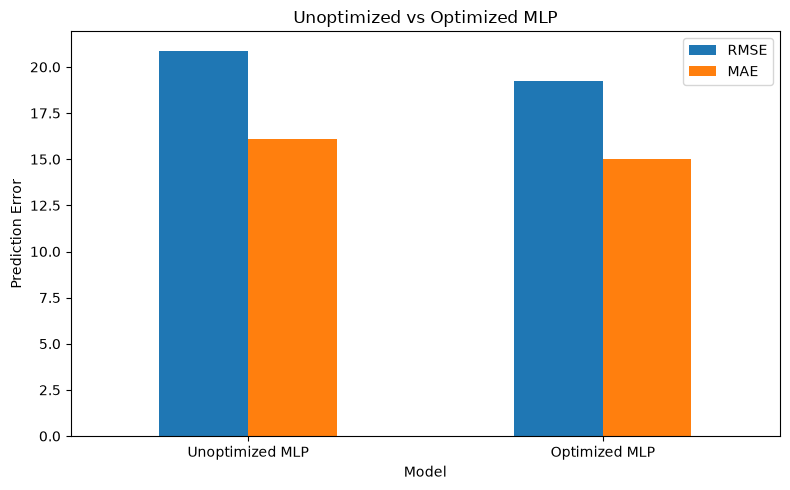

In [21]:
import matplotlib.pyplot as plt

results.set_index("Model")[["RMSE", "MAE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Prediction Error")
plt.title("Unoptimized vs Optimized MLP")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()